In [8]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import r2_score, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

In [9]:
california = fetch_california_housing()
X = pd.DataFrame(california.data, columns=california.feature_names)

features = ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms']
X_selected = X[features]
y = california.target

X_train, X_test, y_train, y_test = train_test_split(X_selected, y, test_size=0.2, random_state=42)

dt_model = DecisionTreeRegressor(max_depth=4, random_state=42)
dt_model.fit(X_train, y_train)

y_pred_dt = dt_model.predict(X_test)
r2_dt = r2_score(y_test, y_pred_dt)

print(f"R² для Decision Tree: {r2_dt:.4f}")

R² для Decision Tree: 0.5075


In [10]:
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)
r2_rf = r2_score(y_test, y_pred_rf)

results_df = pd.DataFrame({
    'Модель': ['Decision Tree (max_depth=4)', 'Random Forest (n_estimators=100)'],
    'R² на тестовій вибірці': [r2_dt, r2_rf]
})

print("Порівняння моделей:")
display(results_df)

Порівняння моделей:


,Модель,R² на тестовій вибірці
0,Decision Tree (max_depth=4),0.507482
1,Random Forest (n_estimators=100),0.587887


In [11]:
xgb_model = XGBRegressor(n_estimators=200, learning_rate=0.1, max_depth=5, random_state=42)
xgb_model.fit(X_train, y_train)

y_pred_xgb = xgb_model.predict(X_test)
r2_xgb = r2_score(y_test, y_pred_xgb)

print(f"R² для XGBoost: {r2_xgb:.4f}")
print(f"R² для Random Forest: {r2_rf:.4f}")
print(f"Різниця (XGBoost - Random Forest): {r2_xgb - r2_rf:.4f}")

R² для XGBoost: 0.5993
R² для Random Forest: 0.5879
Різниця (XGBoost - Random Forest): 0.0114


Метрики класифікації Логістичної Регресії:
Accuracy : 0.7878
Precision: 0.7972
Recall   : 0.7684
F1-score : 0.7825


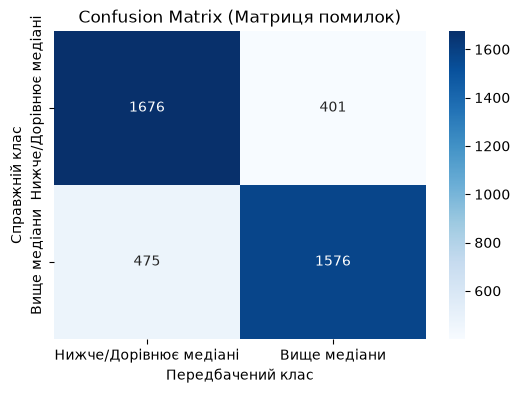

In [ ]:
median_price = np.median(y)
y_class = (y > median_price).astype(int)

X_train_cls, X_test_cls, y_train_cls, y_test_cls = train_test_split(
    X_selected, y_class, test_size=0.2, random_state=42
)

log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train_cls, y_train_cls)

y_pred_cls = log_reg.predict(X_test_cls)

acc = accuracy_score(y_test_cls, y_pred_cls)
prec = precision_score(y_test_cls, y_pred_cls)
rec = recall_score(y_test_cls, y_pred_cls)
f1 = f1_score(y_test_cls, y_pred_cls)
conf_matrix = confusion_matrix(y_test_cls, y_pred_cls)

print("Метрики класифікації Логістичної Регресії:")
print(f"Accuracy : {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall   : {rec:.4f}")
print(f"F1-score : {f1:.4f}")

plt.figure(figsize=(6, 4))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=['Нижче/Дорівнює медіані', 'Вище медіани'], yticklabels=['Нижче/Дорівнює медіані', 'Вище медіани'])
plt.ylabel('Справжній клас')
plt.xlabel('Передбачений клас')
plt.title('Confusion Matrix (Матриця помилок)')
plt.show()